# DHVC 통계 시각화 — Re$_{\delta^*}$ 수렴·검증

MPM-STD `apps/dhvc` 출력(상수물성 OB, fig7)을 시각화한다. 참조 MPM-STD_C 와
출력 형식이 달라 새로 작성 — 우리는 **monitor.csv 가 아니라 로그**에 시계열을,
`dhvc_stats_<step>.dat` 에 **U(z) 프로파일**을 쓴다.

- **로그** `logs/dhvc_<Ra>_<jobid>.log` — 열: step · time · dt · max|div| · Re_dstar(누적) · u_max · sec/step
- **stats** `out_<Ra>/dhvc_stats_<step>.dat` — 헤더에 Re_dstar, 본문 `z  U_mean` (시간·xy 평균)
- **검증**: Re$_{\delta^*}$ = u_max·δ*/ν vs `PaScaL_TCS.csv` (Ra→Re_dstar)

**플롯할 케이스는 아래 `CASES` 리스트에서 직접 지정한다** (자동 수집 아님) — 한 줄에
라벨·로그 파일·stats 폴더. 로그가 아직 없는 케이스(예: 큐 대기 중인 런)는 건너뛰고
알려 준다. 같은 Ra 라도 라벨만 다르면 따로 그린다 (1e8 value 벽 vs mirror 벽 재시작).

실행하면 같은 폴더에 `dhvc_timeseries.png` · `dhvc_profiles.png` · `dhvc_validation.png`
로 저장하고 inline 으로도 띄운다.

In [1]:
import os, re, glob, csv, math
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")   # 노트북: 저장 + 화면
except NameError:
    matplotlib.use("Agg")                                   # 스크립트/배치
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10})

APP_DIR = "/shared/home/wel1come1234/workspace/MPM-STD/apps/dhvc"
if not os.path.isdir(os.path.join(APP_DIR, "plot")):
    APP_DIR = os.path.dirname(os.getcwd())   # plot/ 에서 실행 시 상위
PLOT_DIR = os.path.join(APP_DIR, "plot")
print("APP_DIR =", APP_DIR)

APP_DIR = /shared/home/wel1come1234/workspace/MPM-STD/apps/dhvc


In [2]:
# ── 파서 ──────────────────────────────────────────────────────────────────
def parse_log(path):
    """dhvc 로그 → {step,time,dt,div,re_dstar,u_max, settings}.
    '# step' 헤더 뒤 7열 숫자행 + 로그 앞머리의 **설정 에코**.
    ⚠ stats_start_time 은 ini 가 아니라 이 에코에서 읽는다 — ini 는 런 이후
    수정됐을 수 있다 (실제로 1e7 은 잡 35592 가 60, 35593 이 100 이다)."""
    cols = {k: [] for k in ("step", "time", "dt", "div", "re_dstar", "u_max")}
    extra_names = []          # 7열(step…sec/step) 뒤에 붙는 확장 모니터 열 (Nu_hot, Nu_cold, u_tau_hot …)
    settings, settings_text, nu_header = {}, {}, None
    for line in open(path):
        if line.startswith("# step"):          # 모니터 열 이름 헤더 — 확장 열은 여기서 이름을 얻는다
            names = line[1:].split()
            extra_names = names[6:-1] if len(names) > 7 else []
            for name in extra_names: cols.setdefault(name, [])
            continue
        matched = re.match(r"\s*(\w+)\s*=\s*([-\d.eE+]+)\s*$", line)
        if matched and matched.group(1) not in settings:   # 첫 에코만 (뒤는 무시)
            settings[matched.group(1)] = float(matched.group(2))
        quoted = re.match(r'\s*(\w+)\s*=\s*"(.*)"\s*$', line)   # stats_dir 등
        if quoted and quoted.group(1) not in settings_text:
            settings_text[quoted.group(1)] = quoted.group(2)
        if nu_header is None and line.startswith("# DHVC"):        # 솔버가 쓴 nu
            found = re.search(r"nu=([-\d.eE+]+)", line)
            if found: nu_header = float(found.group(1))
        parts = line.split()
        if len(parts) == 7 + len(extra_names) and not line.lstrip().startswith("#"):
            try:
                v = [float(x) for x in parts]
            except ValueError:
                continue
            cols["step"].append(v[0]); cols["time"].append(v[1]); cols["dt"].append(v[2])
            cols["div"].append(v[3]); cols["re_dstar"].append(v[4]); cols["u_max"].append(v[5])
            for name, value in zip(extra_names, v[6:-1]): cols[name].append(value)
    if not cols["step"]:
        return None
    log = {k: np.array(v) for k, v in cols.items()}
    log["settings"] = settings
    log["settings_text"] = settings_text
    log["nu_header"] = nu_header
    log["path"] = path
    return log

def parse_stats(path):
    """dhvc_stats_*.dat → dict(step,time,re_dstar, z, U, …).
    헤더의 k=v 쌍은 전부 header 로, 열은 마지막 '# z …' 줄의 이름대로 담는다.
    구형 파일(2열 '# z  U_mean')은 z·U 만, 확장 파일(2026-10-07~)은
    V W T urms vrms wrms trms uw uT wT 까지 + header 에 Nu_hot/Nu_cold/u_tau_* 등."""
    header, names = {}, ["z", "U"]
    for line in open(path):
        if not line.startswith("#"): break
        for k, val in re.findall(r"(\w+)=([-\d.eE+]+)", line):
            header[k] = float(val)
        tokens = line[1:].split()
        if tokens and tokens[0] == "z":          # 열 이름 줄
            names = ["z"] + ["U" if t == "U_mean" else t for t in tokens[1:]]
    data = np.loadtxt(path, comments="#")
    out = dict(step=int(header.get("step", 0)), time=header.get("t", 0.0),
               re_dstar=header.get("Re_dstar", float("nan")), header=header,
               columns=names[1:])
    for n, name in enumerate(names[:data.shape[1]]):
        out[name] = data[:, n]
    return out

def reynolds_delta_star(z, U, nu):
    """Re_δ* = u_max·δ*/ν (솔버 정의 1:1) — 프로파일에서 재계산(검산용)."""
    kmax = int(np.argmax(U)); u_max = U[kmax]
    if u_max <= 0: return 0.0, 0, 0.0
    zc = np.concatenate(([0.0], z[:kmax + 1]))
    f = np.concatenate(([1.0], 1.0 - U[:kmax + 1] / u_max))
    dstar = np.trapezoid(f, zc)
    return u_max * dstar / nu, kmax, dstar

def attach_window(case):
    """통계 누적 구간 [t_start, t_end] 를 복원해 case 에 붙인다.

    DHVC 누적은 **dt 가중**이라 (main.cpp:342-345  sum_u += u_bar*dt; sum_dt += dt)
    sum_dt 가 정확히 t_end − t_start 로 망원합된다 → dt 가중 평균 = 그 구간의
    단순 시간평균이고, 구간 길이가 곧 평균 시간이다.

    t_start 정본 : 로그 설정 에코의 stats_start_time (그 런이 실제로 쓴 값)
    독립 검증   : Re_dstar 열은 sum_dt<=0 이면 0 이므로(main.cpp:256 running_re_delta)
                  처음 0 을 벗어나는 모니터 행이 시작을 monitor_interval 안으로 가둔다
    t_end       : 최신 stats 헤더의 t (stats 가 없으면 로그 마지막 t = 누적 진행 중)
    """
    log, stats = case["log"], case["stats"]
    time, re_dstar = log["time"], log["re_dstar"]
    positive = np.flatnonzero(re_dstar > 0)
    if positive.size:                      # [직전 행, 첫 양수 행] 으로 시작을 괄호
        first = int(positive[0])
        bracket = (float(time[first - 1]) if first > 0 else float(time[0]),
                   float(time[first]))
    else:
        bracket = None
    start_setting = log["settings"].get("stats_start_time")
    if bracket is None and start_setting is None:
        case["window"] = None; return None
    if bracket is None:                    # 아직 누적 전 — 예정 시작만 안다
        case["window"] = dict(start=start_setting, end=None, duration=0.0,
                              source="settings echo (not started yet)",
                              bracket=None, started=False, n_snapshots=len(stats),
                              end_step=None)
        return case["window"]
    if start_setting is not None and bracket[0] - 1e-9 <= start_setting <= bracket[1] + 1e-9:
        start, source = start_setting, "settings echo (confirmed by Re_dstar>0)"
    elif start_setting is not None:
        start, source = bracket[1], "Re_dstar>0 (settings echo disagrees)"
        print(f"  [{case['label']}] ⚠ stats_start_time={start_setting:g} 이 "
              f"Re_dstar>0 괄호 [{bracket[0]:.3f}, {bracket[1]:.3f}] 밖이다 "
              f"— 로그 쪽을 쓴다")
    else:
        start, source = bracket[1], "Re_dstar>0 (no settings echo)"
    end = stats[-1]["time"] if stats else float(time[-1])
    end_step = stats[-1]["step"] if stats else int(log["step"][-1])
    # 마지막 stats 쓰기는 **마지막 스텝**에 일어나므로 모니터 마지막 행
    # (monitor_interval 간격) 보다 최대 한 간격만큼 뒤설 수 있다 — 정상이다.
    gap = 2 * float(np.median(np.diff(time))) if time.size > 1 else 0.0
    if stats and not (time[0] - gap <= stats[-1]["time"] <= time[-1] + gap):
        print(f"  [{case['label']}] ⚠ 최신 stats t={stats[-1]['time']:.1f} 가 이 로그의 "
              f"t 범위 [{time[0]:.1f}, {time[-1]:.1f}] (±{gap:.1f}) 밖 "
              f"— 다른 잡이 쓴 파일일 수 있다")
    case["window"] = dict(start=start, end=end, duration=end - start, source=source,
                          bracket=bracket, started=True, n_snapshots=len(stats),
                          end_step=end_step)
    return case["window"]

def window_text(case, short=False):
    """그림 꼬리말 한 줄 — ASCII 만 (DejaVu Sans 에 한글 글리프 없음).
    short=True 는 좁은 그림(6.4in)용 축약형 — 긴 형식은 폭을 넘친다."""
    window = case["window"]
    label = f"Ra={case['label']}"
    if window is None:
        return f"{label}: stats window unknown (no Re_dstar>0 row, no settings echo)"
    if not window["started"]:
        return (f"{label}: stats not started yet - accumulation begins at "
                f"t={window['start']:.1f} (now t={case['log']['time'][-1]:.1f})")
    if short:
        return (f"{label}: avg over t {window['start']:.1f}-{window['end']:.1f}"
                f"  (sum_dt {window['duration']:.1f}, "
                f"{window['n_snapshots']} snaps)")
    text = (f"{label}: dt-weighted average over t {window['start']:.1f}"
            f"-{window['end']:.1f}  (sum_dt = {window['duration']:.1f}")
    if window["n_snapshots"]:
        text += f", {window['n_snapshots']} snapshots, last step {window['end_step']}"
    else:
        text += ", running - no stats file yet"
    return text + f", {window['source']})"

def annotate_windows(figure, annotated, fontsize=7, short=False):
    """모든 그림 하단에 '어디서 어디까지 평균했나' 를 같은 형식으로 적는다."""
    figure.text(0.5, 0.006, "\n".join(window_text(c, short) for c in annotated),
                ha="center", va="bottom", fontsize=fontsize, color="0.35",
                linespacing=1.5)

def shade_window(axis, case, color=None, alpha=0.10):
    """누적 구간을 음영 띠 + 점선 경계로. 아직 시작 전이면 시작선만 긋는다."""
    window = case["window"]
    if window is None:
        return
    if not window["started"]:
        axis.axvline(window["start"], color=color or "tab:purple", lw=0.9, ls="--",
                     alpha=0.7)
        return
    axis.axvspan(window["start"], window["end"], color=color or "tab:purple",
                 alpha=alpha, zorder=0)
    for boundary in (window["start"], window["end"]):
        axis.axvline(boundary, color=color or "tab:purple", lw=0.8, ls=":", zorder=1)

# Ra 라벨 → 수치 (폴백 — 가능하면 case_physics 가 로그 에코를 쓴다)
def ra_value(label):
    """라벨 앞머리의 지수 표기만 읽는다 — '1e8_4gpu' 처럼 꼬리표가 붙어도 된다."""
    matched = re.match(r"\s*(\d+(?:\.\d+)?[eE][+-]?\d+)", label)
    if not matched:
        raise ValueError(f"라벨에서 Ra 를 못 읽었다: {label!r}")
    return float(matched.group(1))

def case_physics(log, label, app_dir):
    """Ra·Pr·nu·stats 디렉터리를 **로그 에코에서** 읽는다 (라벨 규칙보다 우선).

    ⚠ 라벨로 out_<label> 을 찾으면 빗나간다 — 1e8_4gpu 런의 stats_dir 은
    'apps/dhvc/out_1e8' 이라 같은 Ra 의 2-GPU 런과 **같은 폴더를 공유**한다.
    nu 는 솔버가 머리글에 찍은 값을 그대로 쓰고(없으면 sqrt(Pr/Ra) 폴백),
    stats 경로는 basename 만 떼어 app_dir 밑으로 붙인다 (에코는 repo 루트 기준)."""
    settings, text = log["settings"], log["settings_text"]
    rayleigh = settings.get("rayleigh") or ra_value(label)
    prandtl = settings.get("prandtl", 0.7)
    nu = log["nu_header"] if log["nu_header"] else (prandtl / rayleigh) ** 0.5
    stats_dir = os.path.join(app_dir, os.path.basename(text["stats_dir"])) \
        if "stats_dir" in text else os.path.join(app_dir, f"out_{label}")
    return rayleigh, prandtl, nu, stats_dir

# 참조 Re_dstar (PaScaL_TCS.csv: Ra, Re_dstar)
ref = {}
pth = os.path.join(PLOT_DIR, "PaScaL_TCS.csv")
if os.path.exists(pth):
    for row in csv.reader(open(pth)):
        if len(row) == 2:
            ref[float(row[0])] = float(row[1])
def reference_re(ra, tol=0.3):
    for k, v in ref.items():
        if abs(k / ra - 1) < tol: return v
    return None
print("참조 Re_dstar (PaScaL_TCS):", {f"{k:.0e}": round(v, 3) for k, v in ref.items()})

# ── Ng, Ooi, Lohse & Chung (2017) JFM 825 — 상관식(본문) + 디지타이즈 점(fig.8/10) ─────────────
#   PaScaL_TCS.csv 는 그대로 두고(사용자 지시 2026-10-07) 두 번째 참조로 나란히 쓴다.
#   Re_dstar 정의가 우리 dhvc 와 동일(U=max(u), δ*=∫(1−u/U)dz) → 상관식 0.23·Ra^0.28 이 직접 비교 대상.
ng17 = {}            # quantity → dict(prefactor, exponent, ra_min, ra_max, note)
ng17_points = {}     # quantity → (Ra 배열, 값 배열)   디지타이즈 점
def _read_csv_rows(path):
    rows = [r for r in csv.reader(l for l in open(path) if not l.startswith("#")) if r]
    return rows[0], rows[1:]
pth = os.path.join(PLOT_DIR, "ng2017_correlations.csv")
if os.path.exists(pth):
    head, rows = _read_csv_rows(pth)
    for r in rows:
        d = dict(zip(head, r))
        if d["prefactor"]:
            ng17[d["quantity"]] = dict(prefactor=float(d["prefactor"]), exponent=float(d["exponent"]),
                                       ra_min=float(d["ra_min"]), ra_max=float(d["ra_max"]), note=d["note"])
for fname, cols in (("ng2017_fig10_re_dstar.csv", {"Re_dstar": "Re_dstar"}),
                    ("ng2017_fig8.csv", {"Nu": "Nu", "Re_rms": "Re_rms"})):
    pth = os.path.join(PLOT_DIR, fname)
    if not os.path.exists(pth): continue
    head, rows = _read_csv_rows(pth)
    ra_col = np.array([float(r[head.index("Ra")]) for r in rows])
    for key, col in cols.items():
        if col in head:
            ng17_points[key] = (ra_col, np.array([float(r[head.index(col)]) for r in rows]))
def ng17_fit(quantity, ra):
    """Ng 2017 상관식 값 (없으면 None)."""
    f = ng17.get(quantity)
    return None if f is None else f["prefactor"] * np.asarray(ra, float) ** f["exponent"]
def ng17_point(quantity, ra, tol=0.3):
    """디지타이즈 점 중 같은 Ra(±30%) 가 있으면 그 값."""
    if quantity not in ng17_points: return None
    ras, vals = ng17_points[quantity]
    hit = np.flatnonzero(np.abs(ras / ra - 1) < tol)
    return float(vals[hit[0]]) if hit.size else None
print("Ng 2017 상관식:", {k: f"{v['prefactor']}·Ra^{v['exponent']}" for k, v in ng17.items()},
      "| 디지타이즈 점:", {k: len(v[0]) for k, v in ng17_points.items()})


참조 Re_dstar (PaScaL_TCS): {'1e+05': 5.378, '1e+06': 10.43, '1e+07': 22.947, '1e+08': 43.122, '1e+09': 62.963, '1e+10': 89.078}
Ng 2017 상관식: {'Re_dstar': '0.23·Ra^0.28', 'Re_dstar_low_Rif': '1.3·Ra^0.2', 'Nu': '0.0772·Ra^0.32', 'Re_rms': '0.6455·Ra^0.46'} | 디지타이즈 점: {'Re_dstar': 7, 'Nu': 7, 'Re_rms': 7}


In [3]:
# ── 플롯할 케이스를 여기서 직접 지정한다 (리스트 순서 = 범례·표 순서) ──────────
#   label  : 그림·표 이름. 앞머리의 Ra 지수 표기(1e8 …)는 로그 에코가 없을 때만 폴백으로 읽는다
#   log    : 로그 파일 (APP_DIR 기준). 글롭이면 **가장 최근 수정된 1개**
#   stats  : 프로파일 폴더 (APP_DIR 기준). 생략하면 로그 에코의 stats_dir 을 쓴다
#   color / marker / ls : 생략 가능 (기본 tab10 순서 / "o" / "-"). ls 는 시계열·프로파일 선 스타일
# 빼고 싶은 케이스는 줄을 지우거나 주석 처리하면 된다.
CASES = [
    dict(label="1e5",        log="logs/dhvc_1e5_35578.log",            stats="out_1e5"),
    dict(label="1e6",        log="logs/dhvc_1e6_35579.log",            stats="out_1e6"),
    dict(label="1e7",        log="logs/dhvc_1e7_35593.log",            stats="out_1e7"),
    dict(label="1e8 4gpu",   log="logs/dhvc_1e8_4gpu_35641.log",       stats="out_1e8",
         marker="o"),                                                  # value 벽, t 0-150
    dict(label="1e8 mirror", log="logs/dhvc_1e8_4gpu_mirror_35834.log", stats="out_1e8_mirror",
         marker="s", ls="--"),                                         # ck_00180000(t=121.66) 재시작, mirror 벽
    dict(label="1e7 mirror", log="logs/dhvc_1e7_mirror_35992.log",      stats="out_1e7_mirror",
         marker="D", ls="--"),                                         # 1e6 warm start → ck_00020000(t=52.35) 재시작(잡 35992), mirror 벽 + 확장 통계(2026-10-09)
    dict(label="1e8 ext",    log="logs/dhvc_1e8_4gpu_ext_35994.log",    stats="out_1e8_ext",
         marker="P", ls="-."),                                         # 1e7 ext(t=200) warm start, 4 GPU, 과도 30 + 통계 30~130 (2026-10-09)
]

def load_case(spec, index):
    """CASES 한 줄 → case dict. 로그가 없거나 숫자 행이 없으면 None (메시지 출력)."""
    label = spec["label"]
    matches = sorted(glob.glob(os.path.join(APP_DIR, spec["log"])), key=os.path.getmtime)
    if not matches:
        print(f"[{label}] 로그 없음 — 건너뜀 ({spec['log']})"); return None
    log_path = matches[-1]
    log = parse_log(log_path)
    if log is None:
        print(f"[{label}] 로그에 아직 모니터 행이 없음 — 건너뜀 ({os.path.basename(log_path)})")
        return None
    found_job = re.search(r"_(\d+)\.log$", os.path.basename(log_path))
    job = found_job.group(1) if found_job else "?"
    ra, pr, nu, stats_dir = case_physics(log, label, APP_DIR)
    if "stats" in spec:
        stats_dir = os.path.join(APP_DIR, spec["stats"])
    sfiles = sorted(glob.glob(os.path.join(stats_dir, "dhvc_stats_*.dat")),
                    key=lambda p: int(re.search(r"(\d+)", os.path.basename(p)).group(1)))
    stats = [parse_stats(p) for p in sfiles]
    return dict(label=label, job=job, log=log, stats=stats, ra=ra, nu=nu, prandtl=pr,
                stats_dir=stats_dir, log_path=log_path,
                color=spec.get("color", plt.cm.tab10(index % 10)),
                marker=spec.get("marker", "o"), ls=spec.get("ls", "-"))

cases = {}
for index, spec in enumerate(CASES):
    case = load_case(spec, index)
    if case is None: continue
    assert case["label"] not in cases, f"라벨이 겹친다: {case['label']!r}"
    cases[case["label"]] = case
    attach_window(case)
    log = case["log"]
    last_re = log["re_dstar"][-1] if len(log["re_dstar"]) else float("nan")
    tgt = reference_re(case["ra"])
    tgt_s = f"{tgt:.3f} ({100*(last_re/tgt-1):+.1f}%)" if tgt and last_re else "—"
    print(f"[{case['label']:>10}] job {case['job']}: 로그 {len(log['step'])}행 "
          f"t={log['time'][0]:.1f}-{log['time'][-1]:.1f} Re_dstar(누적)={last_re:.3f}  "
          f"vs PaScaL {tgt_s}  / stats {len(case['stats'])}개 "
          f"({os.path.relpath(case['stats_dir'], APP_DIR)}/)")
    print(f"             누적 구간: {window_text(case)}")
assert cases, "로드된 DHVC 케이스가 없다 — 런이 아직 통계를 안 썼을 수 있음"
colors = {lab: c["color"] for lab, c in cases.items()}   # CASES 의 color (기본 tab10 순서)

# ── 누적 구간 요약 표 ─────────────────────────────────────────────────────
# 같은 stats 폴더를 두 케이스가 공유하면 프로파일이 어느 런 것인지 모호해진다
#   (1e8 2-GPU 런과 1e8_4gpu 런이 둘 다 out_1e8 에 쓴다)
shared = {}
for lab, c in cases.items():
    shared.setdefault(c["stats_dir"], []).append(lab)
for stats_dir, labels in shared.items():
    if len(labels) > 1 and cases[labels[0]]["stats"]:
        print(f"⚠ {os.path.basename(stats_dir)}/ 를 {', '.join(labels)} 가 공유한다 "
              f"— 프로파일이 어느 런 것인지 헤더 t 로 확인할 것")

print("\n" + "=" * 131)
print(f"{'case':>12s} {'job':>7s} {'t(log)':>9s} {'stats window t':>18s} "
      f"{'sum_dt':>8s} {'snaps':>6s} {'Re_dstar':>9s} {'PaScaL':>8s} {'dev':>7s} "
      f"{'Ng17fit':>8s} {'dev':>7s} {'Ng17pt':>7s} {'dev':>7s}")
print("-" * 131)
def _dev(v, ref_value):
    return f"{100*(v/float(ref_value)-1):+.1f}%" if ref_value is not None and v else "-"
for lab, c in cases.items():
    w = c["window"]
    if w is None:          span, dur = "-- unknown --", "-"
    elif not w["started"]: span, dur = f"starts at {w['start']:.0f}", "0"
    else:                  span, dur = f"{w['start']:.1f}-{w['end']:.1f}", f"{w['duration']:.1f}"
    re_last = c["log"]["re_dstar"][-1]
    tgt = reference_re(c["ra"])
    fit = ng17_fit("Re_dstar", c["ra"]); pt = ng17_point("Re_dstar", c["ra"])
    print(f"{lab:>12s} {c['job']:>7s} {c['log']['time'][-1]:9.1f} {span:>18s} "
          f"{dur:>8s} {len(c['stats']):6d} {re_last:9.3f} "
          f"{(f'{tgt:.3f}' if tgt else '-'):>8s} {_dev(re_last, tgt):>7s} "
          f"{(f'{float(fit):.2f}' if fit is not None else '-'):>8s} {_dev(re_last, fit):>7s} "
          f"{(f'{pt:.2f}' if pt else '-'):>7s} {_dev(re_last, pt):>7s}")
print("=" * 131)
print("  PaScaL = PaScaL_TCS.csv (기존 참조, 유지) | Ng17fit = 0.23·Ra^0.28 (Ng et al. 2017 fig.10 본문 상관식, 우리 Re_dstar 정의와 동일) "
      "| Ng17pt = 같은 Ra 의 논문 DNS 점(fig.10 디지타이즈, 있을 때만)")


[       1e5] job 35578: 로그 727행 t=0.0-239.7 Re_dstar(누적)=4.790  vs PaScaL 5.378 (-10.9%)  / stats 6개 (out_1e5/)
             누적 구간: Ra=1e5: dt-weighted average over t 60.0-240.0  (sum_dt = 180.0, 6 snapshots, last step 72692, settings echo (confirmed by Re_dstar>0))
[       1e6] job 35579: 로그 972행 t=0.0-239.8 Re_dstar(누적)=10.024  vs PaScaL 10.430 (-3.9%)  / stats 6개 (out_1e6/)
             누적 구간: Ra=1e6: dt-weighted average over t 60.0-240.0  (sum_dt = 180.0, 6 snapshots, last step 97169, settings echo (confirmed by Re_dstar>0))
[       1e7] job 35593: 로그 584행 t=0.0-149.9 Re_dstar(누적)=23.080  vs PaScaL 22.947 (+0.6%)  / stats 2개 (out_1e7/)
             누적 구간: Ra=1e7: dt-weighted average over t 100.0-150.0  (sum_dt = 50.0, 2 snapshots, last step 58324, settings echo (confirmed by Re_dstar>0))
[  1e8 4gpu] job 35641: 로그 2032행 t=0.0-136.6 Re_dstar(누적)=40.975  vs PaScaL 43.122 (-5.0%)  / stats 1개 (out_1e8/)
             누적 구간: Ra=1e8 4gpu: dt-weighted average over t 100.0-125.0  (sum_dt = 

## 1. 시계열 — Re$_{\delta^*}$ 수렴·안정성

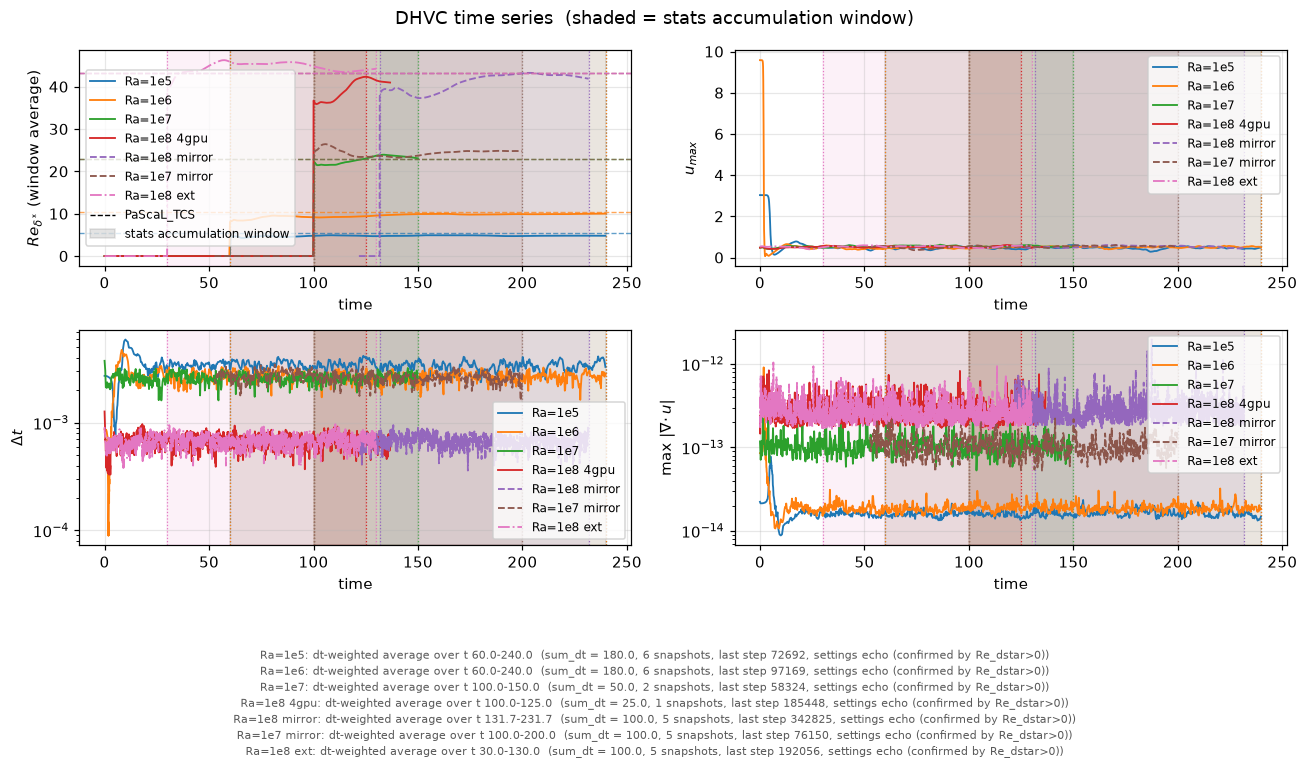

In [4]:
# 그림 안 문자열은 ASCII/mathtext 만 — DejaVu Sans 에 한글 글리프가 없다
panels = [("re_dstar", r"$Re_{\delta^*}$ (window average)", False),
          ("u_max", r"$u_{max}$", False),
          ("dt", r"$\Delta t$", True),
          ("div", r"max $|\nabla\!\cdot u|$", True)]
# 음영 띠 = 각 케이스가 **통계를 누적한 구간** (케이스 색, 네 패널 공통) —
# 평균 구간 동안 dt·div 가 멀쩡했는지 같은 x축에서 바로 읽힌다.
fig, axes = plt.subplots(2, 2, figsize=(12, 7)); axes = axes.ravel()
for ax, (key, ylab, ylog) in zip(axes, panels):
    for lab, c in cases.items():
        shade_window(ax, c, color=colors[lab], alpha=0.10)
        ax.plot(c["log"]["time"], c["log"][key], color=colors[lab], lw=1.2, ls=c["ls"],
                label=f"Ra={lab}")
    if key == "re_dstar":
        for lab, c in cases.items():
            tgt = reference_re(c["ra"])
            if tgt: ax.axhline(tgt, color=colors[lab], ls="--", lw=0.9, alpha=0.7)
        ax.plot([], [], "k--", lw=0.9, label="PaScaL_TCS")
    if ylog: ax.set_yscale("log")
    ax.set_xlabel("time"); ax.set_ylabel(ylab); ax.legend(fontsize=8)
axes[0].axvspan(np.nan, np.nan, color="0.4", alpha=0.18,
                label="stats accumulation window")   # 범례용 더미
axes[0].legend(fontsize=8)
fig.suptitle("DHVC time series  (shaded = stats accumulation window)")
fig.tight_layout(rect=(0, 0.02 + 0.026 * len(cases), 1, 1))
annotate_windows(fig, cases.values())
fig.savefig(os.path.join(PLOT_DIR, "dhvc_timeseries.png"), dpi=150); plt.show()

## 2. 평균 유속 프로파일 $U(z)$ 와 $\delta^*$

[1e5] 프로파일 Re_dstar=4.791 (u_max=0.4659 @ z=0.0981, δ*=0.0272)  헤더값=4.791
       누적 구간: t 60.0-240.0 (sum_dt 180.0)  |  스냅샷별 구간 끝: 90, 120, 150, 180, 210, 240
[1e6] 프로파일 Re_dstar=10.023 (u_max=0.4991 @ z=0.0749, δ*=0.0168)  헤더값=10.023
       누적 구간: t 60.0-240.0 (sum_dt 180.0)  |  스냅샷별 구간 끝: 90, 120, 150, 180, 210, 240
[1e7] 프로파일 Re_dstar=23.076 (u_max=0.5427 @ z=0.0560, δ*=0.0112)  헤더값=23.076
       누적 구간: t 100.0-150.0 (sum_dt 50.0)  |  스냅샷별 구간 끝: 125, 150
[1e8 4gpu] 프로파일 Re_dstar=42.329 (u_max=0.5354 @ z=0.0365, δ*=0.0066)  헤더값=42.329
       누적 구간: t 100.0-125.0 (sum_dt 25.0)  |  스냅샷별 구간 끝: 125
[1e8 mirror] 프로파일 Re_dstar=41.890 (u_max=0.5311 @ z=0.0365, δ*=0.0066)  헤더값=41.890
       누적 구간: t 131.7-231.7 (sum_dt 100.0)  |  스냅샷별 구간 끝: 152, 172, 192, 212, 232
[1e7 mirror] 프로파일 Re_dstar=24.774 (u_max=0.5373 @ z=0.0560, δ*=0.0122)  헤더값=24.774
       누적 구간: t 100.0-200.0 (sum_dt 100.0)  |  스냅샷별 구간 끝: 120, 140, 160, 180, 200
[1e8 ext] 프로파일 Re_dstar=44.234 (u_max=0.5348 @ z=0.0372, δ*=0.0069

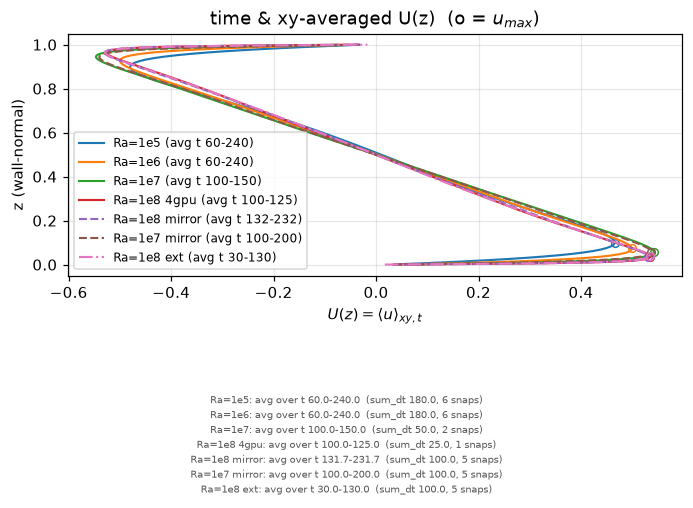

In [5]:
# 각 스냅샷은 **같은 t_start 에서 시작해 그 시각까지 누적**한 러닝 평균이다
# (리셋이 아니다) — 그래서 마지막 스냅샷이 가장 긴 구간 = 가장 수렴된 프로파일.
profiled = [c for c in cases.values() if c["stats"]]
fig, ax = plt.subplots(figsize=(6.4, 4.6))
for lab, c in cases.items():
    if not c["stats"]:
        print(f"[{lab}] stats 아직 없음 — 프로파일 생략 "
              f"({window_text(c)})"); continue
    s = c["stats"][-1]                      # 최신(가장 긴 구간) 프로파일
    w = c["window"]
    ax.plot(s["U"], s["z"], color=colors[lab], lw=1.4, ls=c["ls"],
            label=f"Ra={lab} (avg t {w['start']:.0f}-{s['time']:.0f})")
    re_chk, kmax, dstar = reynolds_delta_star(s["z"], s["U"], c["nu"])
    ax.plot(s["U"][kmax], s["z"][kmax], "o", color=colors[lab], ms=5, mfc="none")
    print(f"[{lab}] 프로파일 Re_dstar={re_chk:.3f} (u_max={s['U'][kmax]:.4f} @ z={s['z'][kmax]:.4f}, "
          f"δ*={dstar:.4f})  헤더값={s['re_dstar']:.3f}")
    print(f"       누적 구간: t {w['start']:.1f}-{s['time']:.1f} "
          f"(sum_dt {s['time'] - w['start']:.1f})  |  스냅샷별 구간 끝: "
          + ", ".join(f"{snapshot['time']:.0f}" for snapshot in c["stats"]))
ax.set_xlabel(r"$U(z)=\langle u\rangle_{xy,t}$"); ax.set_ylabel("z (wall-normal)")
ax.set_title(r"time & xy-averaged U(z)  (o = $u_{max}$)")
ax.legend(fontsize=8)
fig.tight_layout(rect=(0, 0.02 + 0.042 * max(len(profiled), 1), 1, 1))
annotate_windows(fig, profiled, fontsize=6.5, short=True)
fig.savefig(os.path.join(PLOT_DIR, "dhvc_profiles.png"), dpi=150); plt.show()

## 3. 검증 — Re$_{\delta^*}$(Ra) vs 참조 (PaScaL_TCS + Ng et al. 2017 상관식·DNS 점), Nu(Ra)


[1e7 mirror] Nu = 13.461 (hot 13.472, cold 13.449)  vs Ng17 fit 13.416 (+0.3%)
[1e8 ext] Nu = 27.780 (hot 27.799, cold 27.760)  vs Ng17 fit 28.030 (-0.9%)


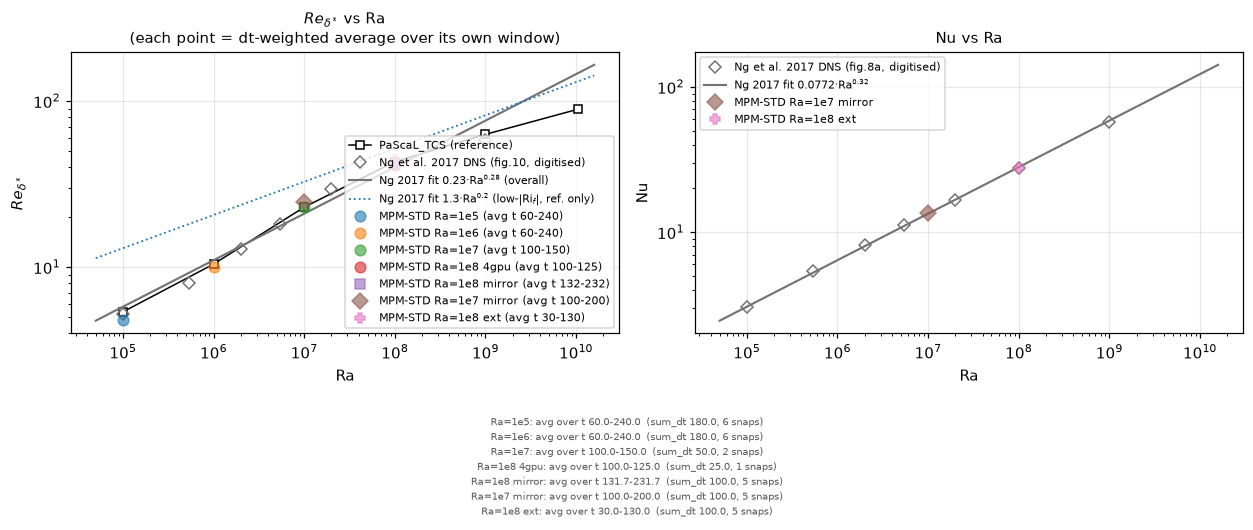


요약 (Re_dstar 는 각 케이스의 누적 구간 평균; 편차는 PaScaL_TCS / Ng 2017 상관식 / Ng 2017 DNS 점 순):
  Ra=       1e5: Re_dstar=  4.790  PaScaL   5.378  -10.9%  Ng17fit   5.78  -17.1%  Ng17pt   5.25   -8.8%  [t 60.0-240.0, sum_dt 180.0]
  Ra=       1e6: Re_dstar= 10.024  PaScaL  10.430   -3.9%  Ng17fit  11.01   -8.9%  Ng17pt      -       -  [t 60.0-240.0, sum_dt 180.0]
  Ra=       1e7: Re_dstar= 23.080  PaScaL  22.947   +0.6%  Ng17fit  20.98  +10.0%  Ng17pt      -       -  [t 100.0-150.0, sum_dt 50.0]
  Ra=  1e8 4gpu: Re_dstar= 40.975  PaScaL  43.122   -5.0%  Ng17fit  39.97   +2.5%  Ng17pt  42.60   -3.8%  [t 100.0-125.0, sum_dt 25.0]
  Ra=1e8 mirror: Re_dstar= 41.891  PaScaL  43.122   -2.9%  Ng17fit  39.97   +4.8%  Ng17pt  42.60   -1.7%  [t 131.7-231.7, sum_dt 100.0]
  Ra=1e7 mirror: Re_dstar= 24.774  PaScaL  22.947   +8.0%  Ng17fit  20.98  +18.1%  Ng17pt      -       -  [t 100.0-200.0, sum_dt 100.0]
  Ra=   1e8 ext: Re_dstar= 44.233  PaScaL  43.122   +2.6%  Ng17fit  39.97  +10.7%  Ng17pt  42.60   +3.8%  

In [6]:
# 참조 둘을 나란히: PaScaL_TCS.csv(기존, 검은 네모) + Ng et al. (2017) JFM 825 — 상관식(선)·DNS 점(회색 마름모).
# Re_dstar 상관식 0.23·Ra^0.28 은 overall(우리 정의와 동일), 1.3·Ra^0.20 은 low-|Ri_f| 조건평균(참고용 점선).
fig, (ax, ax_nu) = plt.subplots(1, 2, figsize=(11.5, 4.8))
ra_line = np.logspace(4.7, 10.2, 200)
ras = np.array(sorted(ref)); res = np.array([ref[r] for r in ras])
ax.plot(ras, res, "ks-", ms=5, mfc="white", lw=1, label="PaScaL_TCS (reference)")
if "Re_dstar" in ng17_points:
    ax.plot(*ng17_points["Re_dstar"], "D", color="0.45", ms=6, mfc="none", label="Ng et al. 2017 DNS (fig.10, digitised)")
if "Re_dstar" in ng17:
    f = ng17["Re_dstar"]
    ax.plot(ra_line, ng17_fit("Re_dstar", ra_line), "-", color="0.45", lw=1.4,
            label=f"Ng 2017 fit {f['prefactor']}·Ra$^{{{f['exponent']}}}$ (overall)")
if "Re_dstar_low_Rif" in ng17:
    f = ng17["Re_dstar_low_Rif"]
    ax.plot(ra_line, ng17_fit("Re_dstar_low_Rif", ra_line), ":", color="tab:blue", lw=1.2,
            label=f"Ng 2017 fit {f['prefactor']}·Ra$^{{{f['exponent']}}}$ (low-|Ri$_f$|, ref. only)")
for lab, c in cases.items():
    re_last = c["log"]["re_dstar"][-1]
    w = c["window"]
    if not (w and w["started"]):           # 아직 누적 전이면 점을 찍을 게 없다
        print(f"[{lab}] 누적 전 — 검증 점 생략 ({window_text(c)})"); continue
    ax.plot(c["ra"], re_last, c["marker"], color=colors[lab], ms=7, alpha=0.6,
            label=f"MPM-STD Ra={lab} (avg t {w['start']:.0f}-{w['end']:.0f})")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Ra"); ax.set_ylabel(r"$Re_{\delta^*}$")
ax.set_title(r"$Re_{\delta^*}$ vs Ra" + "\n(each point = dt-weighted average over its own window)", fontsize=10)
ax.legend(fontsize=7)

# Nu(Ra): 확장 통계가 있는 케이스만 (헤더 Nu_hot/Nu_cold 평균) vs Ng 2017 Nu 상관식·DNS 점
if "Nu" in ng17_points:
    ax_nu.plot(*ng17_points["Nu"], "D", color="0.45", ms=6, mfc="none", label="Ng et al. 2017 DNS (fig.8a, digitised)")
if "Nu" in ng17:
    f = ng17["Nu"]
    ax_nu.plot(ra_line, ng17_fit("Nu", ra_line), "-", color="0.45", lw=1.4,
               label=f"Ng 2017 fit {f['prefactor']}·Ra$^{{{f['exponent']}}}$")
n_nu = 0
for lab, c in cases.items():
    if not c["stats"]: continue
    h = c["stats"][-1].get("header", {})
    if "Nu_hot" in h and "Nu_cold" in h:
        nu_mean = 0.5 * (h["Nu_hot"] + h["Nu_cold"]); n_nu += 1
        ax_nu.plot(c["ra"], nu_mean, c["marker"], color=colors[lab], ms=7, alpha=0.6, label=f"MPM-STD Ra={lab}")
        fit = ng17_fit("Nu", c["ra"])
        print(f"[{lab}] Nu = {nu_mean:.3f} (hot {h['Nu_hot']:.3f}, cold {h['Nu_cold']:.3f})  vs Ng17 fit {float(fit):.3f} ({100*(nu_mean/float(fit)-1):+.1f}%)")
ax_nu.set_xscale("log"); ax_nu.set_yscale("log"); ax_nu.set_xlabel("Ra"); ax_nu.set_ylabel("Nu")
ax_nu.set_title("Nu vs Ra" + ("" if n_nu else "\n(our Nu appears for runs with extended statistics)"), fontsize=10)
ax_nu.legend(fontsize=7)
started = [c for c in cases.values() if c["window"] and c["window"]["started"]]
fig.tight_layout(rect=(0, 0.02 + 0.03 * max(len(started), 1), 1, 1))
annotate_windows(fig, started, fontsize=6.5, short=True)
fig.savefig(os.path.join(PLOT_DIR, "dhvc_validation.png"), dpi=150); plt.show()
print("\n요약 (Re_dstar 는 각 케이스의 누적 구간 평균; 편차는 PaScaL_TCS / Ng 2017 상관식 / Ng 2017 DNS 점 순):")
for lab, c in cases.items():
    re_last = c["log"]["re_dstar"][-1]; w = c["window"]
    tgt = reference_re(c["ra"]); fit = ng17_fit("Re_dstar", c["ra"]); pt = ng17_point("Re_dstar", c["ra"])
    span = (f"t {w['start']:.1f}-{w['end']:.1f}, sum_dt {w['duration']:.1f}" if w and w["started"] else "누적 전")
    print(f"  Ra={lab:>10}: Re_dstar={re_last:7.3f}  PaScaL {(f'{tgt:.3f}' if tgt else '-'):>7s} {_dev(re_last, tgt):>7s}"
          f"  Ng17fit {(f'{float(fit):.2f}' if fit is not None else '-'):>6s} {_dev(re_last, fit):>7s}"
          f"  Ng17pt {(f'{pt:.2f}' if pt else '-'):>6s} {_dev(re_last, pt):>7s}  [{span}]")


## 4. 확장 통계 — 온도·rms·플럭스·수지 (2026-10-07 이후 런)

`dhvc_stats_*.dat` 에 V W T, rms(u v w T), ⟨u′w′⟩ ⟨u′T′⟩ ⟨w′T′⟩ 열과 헤더에 Nu_hot/Nu_cold, u_tau_hot/cold,
t_start/sum_dt/mean_dPdx 가 들어 있는 케이스만 그린다 (구형 2열 파일은 건너뜀). 플럭스는 **슬롯곱**(U x-면·W z-면·T 중심, 보간 없음).

수지 검산 — 둘 다 z 에 대해 **평평**해야 수렴한 통계다:
- 열: q(z) = ⟨w′T′⟩ − α d⟨T⟩/dz = Nu·α (α = 1/√(Ra·Pr), ΔT = lz = 1)
- 운동량(x 주기·중력 x): τ(z) = ν dU/dz − ⟨u′w′⟩ + ∫₀ᶻ(⟨T⟩ − ⟨dP/dx⟩)dz′ = τ_w,hot


[1e7 mirror] Nu_hot=13.472 Nu_cold=13.449 u_tau_hot=0.09926 u_tau_cold=0.09961 mean_dPdx=9.557e-04  q/α 범위 12.909~14.122  tau 범위 9.361e-03~1.021e-02
[1e8 ext] Nu_hot=27.799 Nu_cold=27.760 u_tau_hot=0.07515 u_tau_cold=0.07491 mean_dPdx=-2.231e-04  q/α 범위 27.242~28.354  tau 범위 5.494e-03~5.853e-03


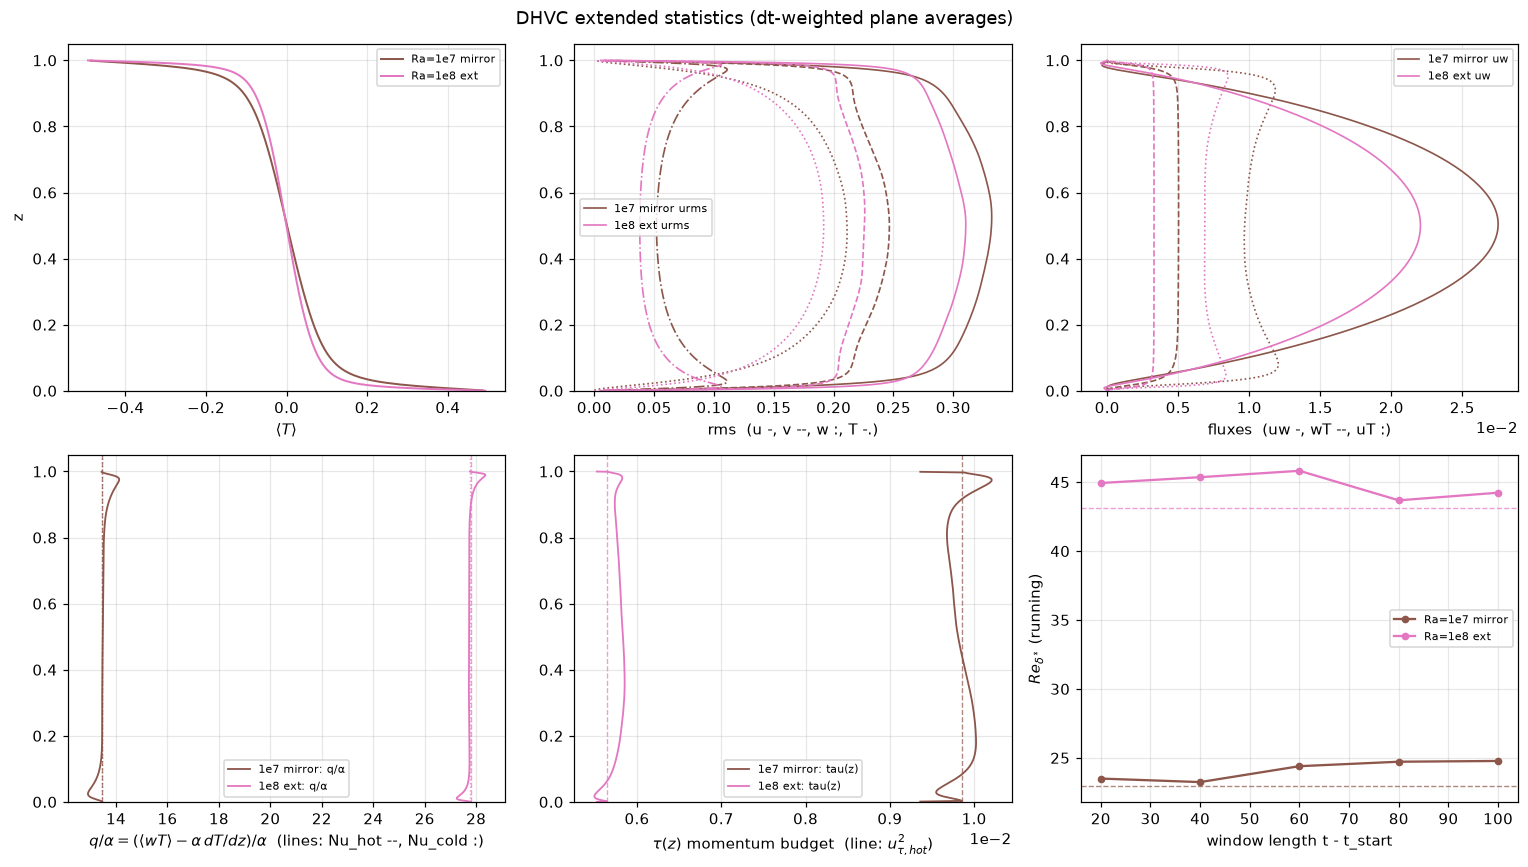

In [7]:
extended = [c for c in cases.values() if c["stats"] and "T" in c["stats"][-1]]
if not extended:
    print("확장 통계가 있는 케이스 없음 — 2026-10-07 이후 런부터 생긴다")
else:
    fig, axes = plt.subplots(2, 3, figsize=(14, 8)); axes = axes.ravel()
    for c in extended:
        s = c["stats"][-1]; h = s["header"]; lab = c["label"]; col = colors[lab]
        z, U, T = s["z"], s["U"], s["T"]
        nu_c = c["nu"]; alpha = 1.0 / np.sqrt(c["ra"] * c["prandtl"])
        axes[0].plot(T, z, color=col, lw=1.3, label=f"Ra={lab}")
        for key, ls in (("urms", "-"), ("vrms", "--"), ("wrms", ":"), ("trms", "-.")):
            if key in s: axes[1].plot(s[key], z, color=col, lw=1.1, ls=ls,
                                      label=f"{lab} {key}" if key == "urms" else None)
        for key, ls in (("uw", "-"), ("wT", "--"), ("uT", ":")):
            if key in s: axes[2].plot(s[key], z, color=col, lw=1.1, ls=ls,
                                      label=f"{lab} {key}" if key == "uw" else None)
        # 열 수지: q = ⟨wT⟩ − α dT/dz  (벽에서 Nu·α 와 비교)
        dTdz = np.gradient(T, z)
        q = s["wT"] - alpha * dTdz
        axes[3].plot(q / alpha, z, color=col, lw=1.2, label=f"{lab}: q/α")
        for key, ls in (("Nu_hot", "--"), ("Nu_cold", ":")):
            if key in h: axes[3].axvline(h[key], color=col, ls=ls, lw=0.9, alpha=0.7)
        # 운동량 수지: τ = ν dU/dz − ⟨uw⟩ + ∫(T − dPdx) dz
        dUdz = np.gradient(U, z)
        zc = np.concatenate(([0.0], z)); Tc = np.concatenate(([0.5], T))
        body = np.cumsum(0.5 * (Tc[1:] + Tc[:-1] - 2 * h.get("mean_dPdx", 0.0)) * np.diff(zc))
        tau = nu_c * dUdz - s["uw"] + body
        axes[4].plot(tau, z, color=col, lw=1.2, label=f"{lab}: tau(z)")
        if "u_tau_hot" in h: axes[4].axvline(h["u_tau_hot"] ** 2, color=col, ls="--", lw=0.9, alpha=0.7)
        # 창 길이에 따른 Re_dstar 수렴 (스냅샷별)
        axes[5].plot([snap["time"] - snap["header"].get("t_start", np.nan) for snap in c["stats"]],
                     [snap["re_dstar"] for snap in c["stats"]], "o-", color=col, ms=4, label=f"Ra={lab}")
        tgt = reference_re(c["ra"])
        if tgt: axes[5].axhline(tgt, color=col, ls="--", lw=0.9, alpha=0.7)
        print(f"[{lab}] Nu_hot={h.get('Nu_hot', np.nan):.3f} Nu_cold={h.get('Nu_cold', np.nan):.3f} "
              f"u_tau_hot={h.get('u_tau_hot', np.nan):.5f} u_tau_cold={h.get('u_tau_cold', np.nan):.5f} "
              f"mean_dPdx={h.get('mean_dPdx', np.nan):.3e}  q/α 범위 {np.nanmin(q/alpha):.3f}~{np.nanmax(q/alpha):.3f}  "
              f"tau 범위 {np.nanmin(tau):.3e}~{np.nanmax(tau):.3e}")
    axes[0].set_xlabel(r"$\langle T\rangle$"); axes[0].set_ylabel("z")
    axes[1].set_xlabel("rms  (u -, v --, w :, T -.)"); axes[2].set_xlabel("fluxes  (uw -, wT --, uT :)")
    axes[3].set_xlabel(r"$q/\alpha = (\langle wT\rangle - \alpha\,dT/dz)/\alpha$  (lines: Nu_hot --, Nu_cold :)")
    axes[4].set_xlabel(r"$\tau(z)$ momentum budget  (line: $u_{\tau,hot}^2$)")
    axes[5].set_xlabel("window length t - t_start"); axes[5].set_ylabel(r"$Re_{\delta^*}$ (running)")
    for ax in axes[:5]: ax.set_ylim(0, None)
    for ax in axes[2:5]: ax.ticklabel_format(axis="x", style="sci", scilimits=(-2, 2))  # 작은 플럭스 눈금 겹침 방지
    for ax in axes: ax.legend(fontsize=7)
    fig.suptitle("DHVC extended statistics (dt-weighted plane averages)")
    fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, "dhvc_extended.png"), dpi=150); plt.show()


## 5. 논문 통계량 — 조건평균·면적비·|Ri$_f$| PDF·국소 Nu·스펙트럼 (Ng et al. 2017 fig.4–11)

`dhvc_conditional_*.dat`(low/high-|Ri$_f$| 조건평균, ρ, Nu$_l$/Nu$_h$), `dhvc_richardson_pdf_*.dat`(히스토그램), `dhvc_spectra_*.dat`(E$_{uu}$(k$_x$;z), E$_{uu}$(k$_y$;z))
가 있는 케이스만 그린다. 벽 단위는 그 케이스 `dhvc_stats` 헤더의 u_tau_hot·theta_tau_hot (hot 벽 쪽). 로그 법칙 상수는 논문 (6.1): κ=0.41, A=5.0, Pr$_t$=0.85, B=3.8.


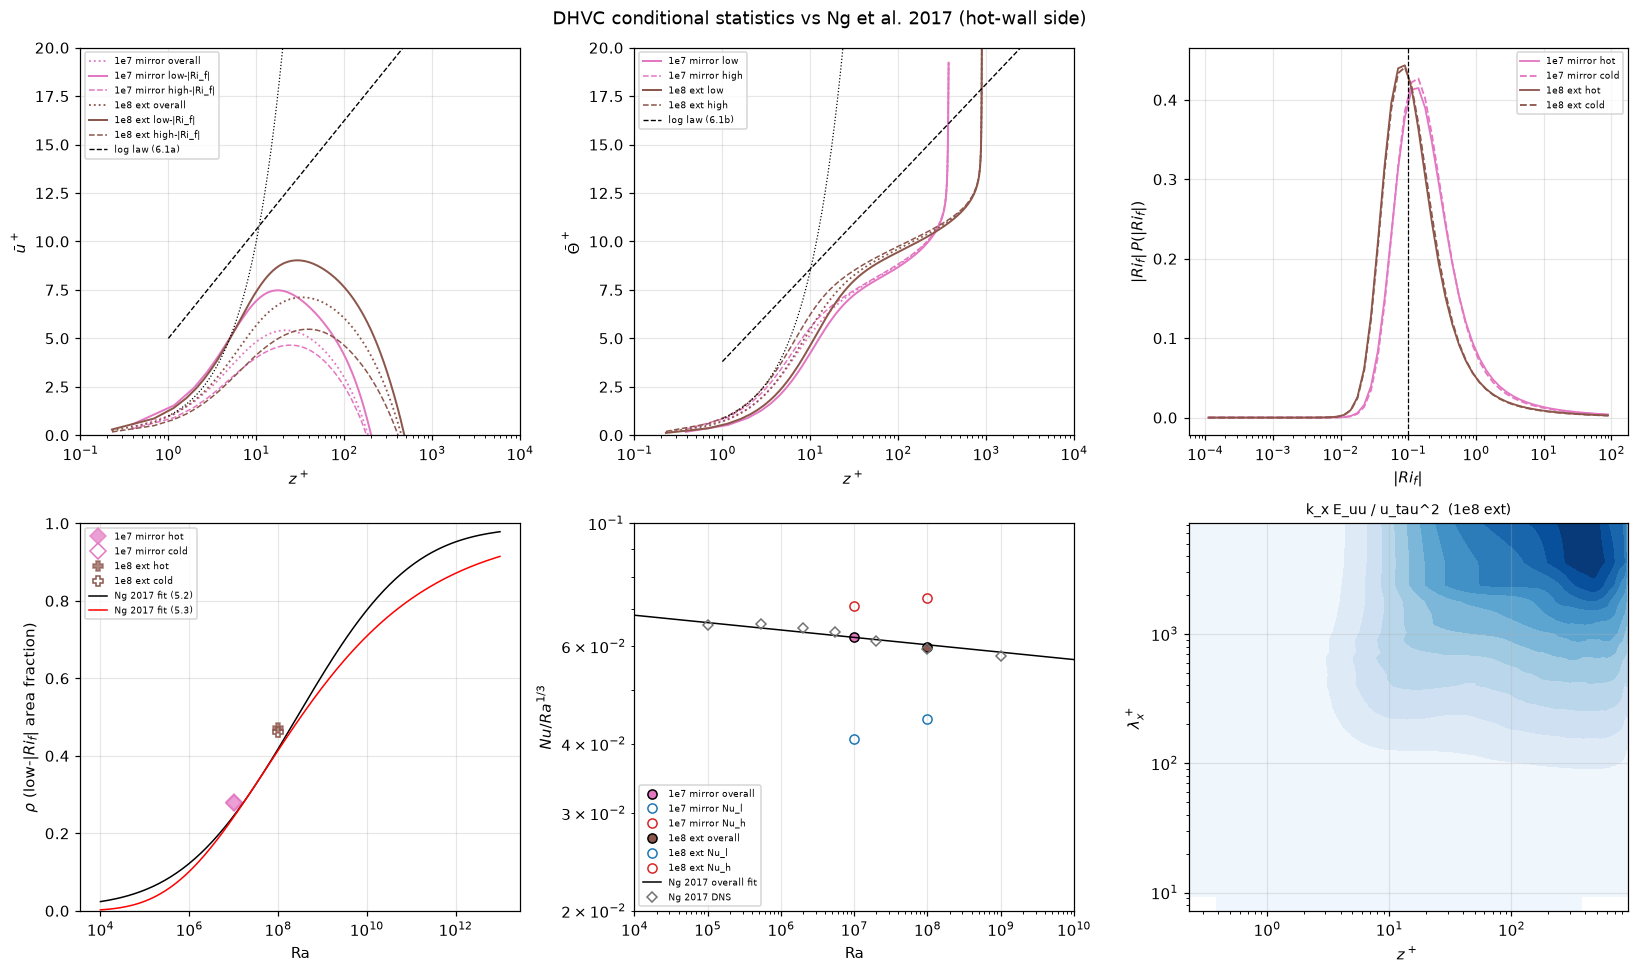

        case  rho_hot rho_cold       Nu     Nu_l     Nu_h Re_dstar_l  Ng fit_l
  1e7 mirror    0.281    0.277   13.461    8.795   15.264      31.05     32.65
     1e8 ext    0.471    0.462   27.780   20.593   34.069      52.23     51.75


In [8]:
# ── 파서 (새 파일 3종) ───────────────────────────────────────────────────────
def _header_kv(path):
    h, names = {}, []
    for line in open(path):
        if not line.startswith("#"): break
        for k, val in re.findall(r"(\w+)=([-\d.eE+]+|nan|inf)", line): h[k] = float(val)
        tokens = line[1:].split()
        if tokens and tokens[0] == "z": names = tokens[1:]
    return h, names
def parse_conditional(path):
    h, names = _header_kv(path); d = np.loadtxt(path, comments="#")
    out = dict(header=h, z=d[:, 0]); out.update({n: d[:, i + 1] for i, n in enumerate(names)}); return out
def parse_richardson_pdf(path):
    h, _ = _header_kv(path); d = np.loadtxt(path, comments="#")
    return dict(header=h, log10=d[:, 0], hot=d[:, 1], cold=d[:, 2])
def parse_spectra(path):
    h, _ = _header_kv(path); blocks, cur = {}, None
    for line in open(path):
        if line.startswith("# block"): cur = line.split()[2]; blocks[cur] = []
        elif not line.startswith("#") and cur: blocks[cur].append(np.fromstring(line, sep=" "))
    out = dict(header=h)
    for k, rows in blocks.items():
        a = np.array(rows); out["z_" + k] = a[:, 0]; out["E_" + k] = a[:, 1:]
    return out
def latest(stats_dir, pattern):
    files = sorted(glob.glob(os.path.join(stats_dir, pattern)), key=lambda p: int(re.search(r"(\d+)\.dat$", p).group(1)))
    return files[-1] if files else None

paper = [c for c in cases.values() if c["stats"] and latest(c["stats_dir"], "dhvc_conditional_*.dat")]
if not paper:
    print("조건평균·PDF·스펙트럼 파일이 있는 케이스 없음 (2026-10-07 통계 확장 이후 런부터)")
else:
    KAPPA, A_LOG, PR_T, B_LOG = 0.41, 5.0, 0.85, 3.8
    fig, axes = plt.subplots(2, 3, figsize=(15, 9)); axes = axes.ravel()
    summary = []
    for c in paper:
        lab, col = c["label"], colors[lab]; h = c["stats"][-1]["header"]; s = c["stats"][-1]
        cond = parse_conditional(latest(c["stats_dir"], "dhvc_conditional_*.dat"))
        pdf = parse_richardson_pdf(latest(c["stats_dir"], "dhvc_richardson_pdf_*.dat"))
        spec_path = latest(c["stats_dir"], "dhvc_spectra_*.dat")
        nu_c = c["nu"]; u_tau = h.get("u_tau_hot", np.nan); theta_tau = h.get("theta_tau_hot", np.nan)
        zp = cond["z"] * u_tau / nu_c
        # (a) 조건 평균 속도 ū⁺ (hot 벽): overall(점선), low(실선), high(파선)   — fig.7a,c,e
        axes[0].plot(zp, s["U"] / u_tau, ":", color=col, lw=1.2, label=f"{lab} overall")
        axes[0].plot(zp, cond["U_low_hot"] / u_tau, "-", color=col, lw=1.3, label=f"{lab} low-|Ri_f|")
        axes[0].plot(zp, cond["U_high_hot"] / u_tau, "--", color=col, lw=1.0, label=f"{lab} high-|Ri_f|")
        # (b) 조건 평균 온도 Θ̄⁺ = (Θ_h − Θ̄)/θ_τ                                    — fig.7b,d,f
        axes[1].plot(zp, (0.5 - s["T"]) / theta_tau, ":", color=col, lw=1.2)
        axes[1].plot(zp, (0.5 - cond["T_low_hot"]) / theta_tau, "-", color=col, lw=1.3, label=f"{lab} low")
        axes[1].plot(zp, (0.5 - cond["T_high_hot"]) / theta_tau, "--", color=col, lw=1.0, label=f"{lab} high")
        # (c) |Ri_f| premultiplied PDF  |Ri_f|·P(|Ri_f|) = P(log10|Ri_f|)/ln10          — fig.4b
        width = (pdf["header"]["log10_max"] - pdf["header"]["log10_min"]) / pdf["header"]["bins"]
        for side, ls in (("hot", "-"), ("cold", "--")):
            total = pdf[side].sum() + pdf["header"].get(f"underflow_{side}", 0) + pdf["header"].get(f"overflow_{side}", 0)
            if total > 0:
                p_log = pdf[side] / (total * width)
                axes[2].plot(10 ** pdf["log10"], p_log / np.log(10), ls, color=col, lw=1.2, label=f"{lab} {side}")
        # (d) 면적비 ρ vs Ra (논문 (5.2)(5.3) 피팅)                                        — fig.6
        rho_h, rho_c = cond["header"]["rho_hot"], cond["header"]["rho_cold"]
        axes[3].plot(c["ra"], rho_h, c["marker"], color=col, ms=7, alpha=0.7, label=f"{lab} hot")
        axes[3].plot(c["ra"], rho_c, c["marker"], color=col, ms=7, mfc="none", label=f"{lab} cold")
        # (e) 국소 Nu: Nu_l·Nu_h (hot/cold 평균) 와 overall, 보상형 Nu/Ra^{1/3}            — fig.8a
        nu_l = np.nanmean([cond["header"].get("Nu_low_hot", np.nan), cond["header"].get("Nu_low_cold", np.nan)])
        nu_hh = np.nanmean([cond["header"].get("Nu_high_hot", np.nan), cond["header"].get("Nu_high_cold", np.nan)])
        nu_all = 0.5 * (h["Nu_hot"] + h["Nu_cold"])
        axes[4].plot(c["ra"], nu_all / c["ra"] ** (1 / 3), "o", color="k", ms=6, mfc=col, label=f"{lab} overall")
        axes[4].plot(c["ra"], nu_l / c["ra"] ** (1 / 3), "o", color="tab:blue", ms=6, mfc="none", label=f"{lab} Nu_l")
        axes[4].plot(c["ra"], nu_hh / c["ra"] ** (1 / 3), "o", color="tab:red", ms=6, mfc="none", label=f"{lab} Nu_h")
        # (f) premultiplied 스펙트럼 k_x E_uu/u_τ² — (z⁺, λ_x⁺) 등고선 (마지막 케이스만)        — fig.11a
        if spec_path:
            sp = parse_spectra(spec_path); lx = sp["header"]["lx"]; E = sp["E_x"][:, 1:]
            m = np.arange(1, E.shape[1] + 1); kx = 2 * np.pi * m / lx       # m = 0(평균²) 제외
            zp_s = sp["z_x"] * u_tau / nu_c; lam_p = (2 * np.pi / kx) * u_tau / nu_c
            Z, L = np.meshgrid(zp_s, lam_p, indexing="ij")
            pm = (kx[None, :] * E) / u_tau ** 2
            cs = axes[5].contourf(Z, L, pm, levels=12, cmap="Blues"); axes[5].set_title(f"k_x E_uu / u_tau^2  ({lab})", fontsize=9)
        # Re_δ*,l: low-|Ri_f| 조건 프로파일의 U=max(ū_l), δ*_l                            — fig.10 blue
        ul = cond["U_low_hot"]; k = int(np.argmax(ul)); um = ul[k]
        zc = np.concatenate(([0.0], cond["z"][:k + 1])); f = np.concatenate(([1.0], 1 - ul[:k + 1] / um))
        re_l = um * np.trapezoid(f, zc) / nu_c if um > 0 else np.nan
        fit_l = ng17_fit("Re_dstar_low_Rif", c["ra"])
        summary.append((lab, rho_h, rho_c, nu_all, nu_l, nu_hh, re_l, float(fit_l) if fit_l is not None else np.nan))
    # 기준선·꾸밈
    zz = np.logspace(0, 3.5, 100)
    axes[0].plot(zz, zz, "k:", lw=0.8); axes[0].plot(zz, np.log(zz) / KAPPA + A_LOG, "k--", lw=0.9, label="log law (6.1a)")
    axes[1].plot(zz, PR_T * zz, "k:", lw=0.8); axes[1].plot(zz, PR_T * np.log(zz) / KAPPA + B_LOG, "k--", lw=0.9, label="log law (6.1b)")
    for ax, yl in ((axes[0], r"$\bar u^+$"), (axes[1], r"$\bar\Theta^+$")):
        ax.set_xscale("log"); ax.set_xlim(0.1, 1e4); ax.set_ylim(0, 20); ax.set_xlabel(r"$z^+$"); ax.set_ylabel(yl); ax.legend(fontsize=6)
    axes[2].set_xscale("log"); axes[2].set_xlabel(r"$|Ri_f|$"); axes[2].set_ylabel(r"$|Ri_f|\,P(|Ri_f|)$"); axes[2].axvline(0.1, color="k", ls="--", lw=0.8); axes[2].legend(fontsize=6)
    ra_line = np.logspace(4, 13, 200)
    axes[3].plot(ra_line, 0.49 * np.vectorize(math.erf)(0.35 * np.log10(ra_line) - 2.95) + 0.5, "k-", lw=1, label="Ng 2017 fit (5.2)")
    axes[3].plot(ra_line, 0.99 * np.exp(-2.21 * np.exp(-0.48 * np.log10(ra_line) + 2.91)), "r-", lw=1, label="Ng 2017 fit (5.3)")
    axes[3].set_xscale("log"); axes[3].set_xlabel("Ra"); axes[3].set_ylabel(r"$\rho$ (low-$|Ri_f|$ area fraction)"); axes[3].set_ylim(0, 1); axes[3].legend(fontsize=6)
    if "Nu" in ng17:
        fnu = ng17["Nu"]; axes[4].plot(ra_line, fnu["prefactor"] * ra_line ** (fnu["exponent"] - 1 / 3), "k-", lw=1, label="Ng 2017 overall fit")
    if "Nu" in ng17_points:
        axes[4].plot(ng17_points["Nu"][0], ng17_points["Nu"][1] / ng17_points["Nu"][0] ** (1 / 3), "D", color="0.45", mfc="none", ms=5, label="Ng 2017 DNS")
    axes[4].set_xscale("log"); axes[4].set_xlim(1e4, 1e10); axes[4].set_ylim(0.02, 0.10); axes[4].set_yscale("log"); axes[4].set_xlabel("Ra"); axes[4].set_ylabel(r"$Nu/Ra^{1/3}$"); axes[4].legend(fontsize=6)
    axes[5].set_xscale("log"); axes[5].set_yscale("log"); axes[5].set_xlabel(r"$z^+$"); axes[5].set_ylabel(r"$\lambda_x^+$")
    fig.suptitle("DHVC conditional statistics vs Ng et al. 2017 (hot-wall side)")
    fig.tight_layout(); fig.savefig(os.path.join(PLOT_DIR, "dhvc_conditional.png"), dpi=150); plt.show()
    print(f"{'case':>12s} {'rho_hot':>8s} {'rho_cold':>8s} {'Nu':>8s} {'Nu_l':>8s} {'Nu_h':>8s} {'Re_dstar_l':>10s} {'Ng fit_l':>9s}")
    for lab, rh, rc, nu_all, nl, nh, re_l, fit_l in summary:
        print(f"{lab:>12s} {rh:8.3f} {rc:8.3f} {nu_all:8.3f} {nl:8.3f} {nh:8.3f} {re_l:10.2f} {fit_l:9.2f}")
